# 05 Train the random forest

A random forest is many decision trees. Each tree asks yes/no questions about the 14 numbers, each is trained on a
slightly different random part of the data, and then they vote. A forest can give 8 answers at once, one per defect.

I train it, check if it learned or memorised, try a few settings on validation, look at which numbers it uses and
time it. The test part stays closed until 06.

Saves `output/forest.joblib`.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

import wafer

f = np.load("output/features.npz")
X_train, y_train = f["X_train"], f["y_train"]
X_val, y_val = f["X_val"], f["y_val"]

baseline = joblib.load("output/baseline.joblib") # from 04, to compare with

## 1. Train it

`n_estimators` is the number of trees, `random_state=42` gives the same forest every run, `n_jobs=-1` uses every
core of the laptop so training is faster.

In [2]:
# n_estimators = number of trees, random_state = same forest every run, n_jobs=-1 = use all cores (faster)
forest = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
start = time.perf_counter() # the time right now in seconds
forest.fit(X_train, y_train)
print(f"Trained in {time.perf_counter() - start:.1f} s")

Trained in 0.7 s


## 2. Learned or memorised?

A model that memorises its training wafers scores perfect on them and badly on new ones (overfitting). So I score
it on both parts and look at the gap.

In [3]:
# score on the wafers it trained on vs wafers it never saw
f1_train = f1_score(y_train, forest.predict(X_train), average=None)
f1_val = f1_score(y_val, forest.predict(X_val), average=None)

for i in range(8):
    # big gap = it memorised the training wafers
    print(f"{wafer.DEFECTS[i]}: training {f1_train[i]:.2f}, validation {f1_val[i]:.2f}, gap {f1_train[i] - f1_val[i]:.2f}")

Center: training 1.00, validation 0.93, gap 0.07
Donut: training 1.00, validation 0.94, gap 0.06
Edge-Loc: training 1.00, validation 0.88, gap 0.12
Edge-Ring: training 1.00, validation 0.94, gap 0.06
Loc: training 1.00, validation 0.92, gap 0.08
Near-Full: training 1.00, validation 0.98, gap 0.02
Scratch: training 1.00, validation 0.81, gap 0.19
Random: training 1.00, validation 0.78, gap 0.22


**What to look for:** which defect has the biggest gap. A small gap is normal, a big one means memorising.

## 3. Try a few settings

I try more trees, and `class_weight="balanced"`, which gives the rarer answers more weight. I keep the one with the
highest **lowest** F1, because the weakest defect matters most. Only validation is used, so the test stays fair.

In [4]:
settings = {
    "100 trees": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "300 trees": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "1000 trees": RandomForestClassifier(n_estimators=1000, random_state=42, n_jobs=-1),
    # balanced = rare answers count more. "yes scratch" is rare so it tries harder to not miss those
    "300 trees balanced": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
    "1000 trees balanced": RandomForestClassifier(n_estimators=1000, class_weight="balanced", random_state=42, n_jobs=-1),
}

# start at 0 so the first one always wins, then the others have to beat it
best_lowest = 0
for name in settings:
    model = settings[name]
    model.fit(X_train, y_train)
    predicted = model.predict(X_val)
    lowest = f1_score(y_val, predicted, average=None).min() # the F1 of the worst defect
    print(f"{name}: all 8 right {accuracy_score(y_val, predicted) * 100:.1f}%, lowest F1 {lowest:.2f}")

    # better worst defect than before? keep this one
    if lowest > best_lowest:
        best_lowest = lowest
        forest = model
        kept = name

print("Kept:", kept)
print(f"Baseline from 04: all 8 right {accuracy_score(y_val, baseline.predict(X_val)) * 100:.1f}%")

100 trees: all 8 right 67.8%, lowest F1 0.78


300 trees: all 8 right 68.7%, lowest F1 0.77


1000 trees: all 8 right 68.7%, lowest F1 0.78


300 trees balanced: all 8 right 67.8%, lowest F1 0.81


1000 trees balanced: all 8 right 67.9%, lowest F1 0.80
Kept: 300 trees balanced
Baseline from 04: all 8 right 30.5%


**What to look for:** do more trees help, or only cost time? And is the forest clearly above the baseline?

## 4. Which numbers does it use most?

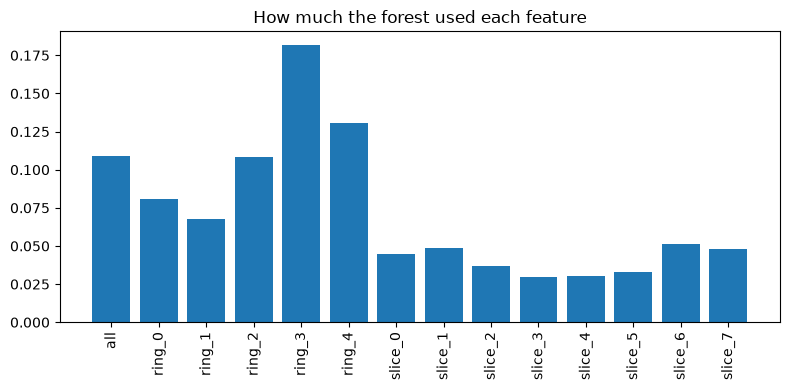

In [5]:
plt.figure(figsize=(8, 4))
# feature_importances_ = how much the trees used each of the 14 numbers, adds up to 1
plt.bar(wafer.FEATURE_NAMES, forest.feature_importances_)
plt.xticks(rotation=90) # turn the names so they dont overlap
plt.title("How much the forest used each feature")
plt.tight_layout()
plt.show()

## 5. How fast is it?

In a factory a wafer has to be checked as it comes off the line: under 50 ms per wafer, and 1000 wafers under 10 s.
I time it from map to answer, so the features are included. For one wafer I switch to one core: starting a worker
on every core costs more than the prediction itself.

In [6]:
maps_val = np.load("output/split.npz")["maps_val"]

forest.set_params(n_jobs=1) # 1 core, for 1 wafer starting all cores is slower than the actual work
start = time.perf_counter()
for m in maps_val[:50]:
    forest.predict([wafer.features(m)]) # [ ] because predict wants a table, this is a table with 1 row
one_wafer_ms = (time.perf_counter() - start) / 50 * 1000 # /50 for one wafer, *1000 for ms
print(f"One wafer: {one_wafer_ms:.1f} ms")

forest.set_params(n_jobs=-1)
start = time.perf_counter()
forest.predict([wafer.features(m) for m in maps_val[:1000]])
print(f"1000 wafers: {time.perf_counter() - start:.2f} s")

One wafer: 8.6 ms
1000 wafers: 0.19 s


## 6. Save

In [7]:
joblib.dump(forest, "output/forest.joblib", compress=3) # compress because a forest file gets big
print("Saved output/forest.joblib")

Saved output/forest.joblib
